# Sensitivity maps and array scaling

The source electron rate scales exactly as $10^{-0.4 m}$ with magnitude, so the ETC can evaluate
the SNR on a (magnitude, exposure time) grid without redoing the spectrum each time, and it can
solve the limiting magnitude for a given SNR and exposure analytically, bin by bin. This notebook
builds those maps for both instruments and then asks how they move with the number of
telescopes, which is still an open design choice for LFAST.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lfast_etc import LFASTETC, Source, Telescope, Instrument, Sky, list_instruments
from lfast_etc.plotting import plot_snr_map, plot_limiting_magnitude, plot_vs_n_telescopes, equivalent_diameter_axis
try:
    plt.style.use('gks')      # the author's matplotlib style; skipped if you do not have it
except OSError:
    pass

## Bench: SNR per resel versus V magnitude and exposure time

The map is the median SNR over 500 to 650 nm. Read it along a horizontal line to see how the SNR
grows with time at fixed magnitude, or along a contour to see how much fainter a longer exposure
reaches. The magnitude of the source object does not matter here; the grid supplies it.

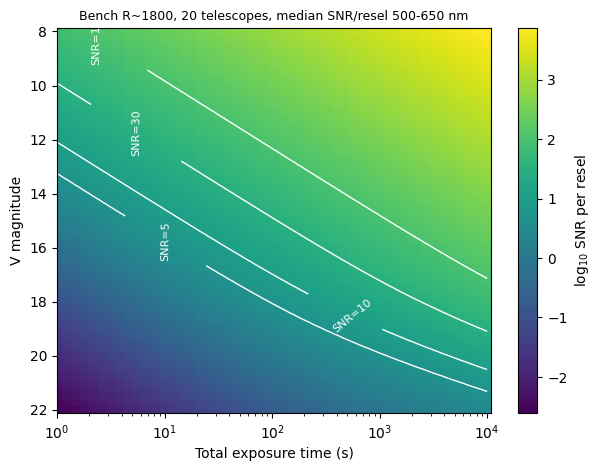

In [2]:
bench = LFASTETC("bench_r1800", n_telescopes=20)
gstar = Source.blackbody(5800, mag=0, band="V")
mags = np.linspace(8, 22, 57)
exps = np.logspace(0, 4, 49)                     # 1 s to about 3 h
snr = bench.snr_grid(gstar, mags, exps, wavelength=(500, 650))
plot_snr_map(mags, exps, snr, band="V", title="Bench R~1800, 20 telescopes, median SNR/resel 500-650 nm");

Where the contours are straight lines of slope $-2.5$ mag per decade of time the measurement is
photon limited by the star. They bend at the faint end where sky and read noise enter and the gain
per unit time slows down. Following the SNR = 10 contour, a V ~ 18.9 star reaches it in 15 min; the
gain drops from 2.5 mag per decade at the bright end to 1.5 mag between 1000 and 10,000 s.

## CSHELL: SNR per resel versus H magnitude

Same map for CSHELL in its native R = 18,000 mode, for one echelle setting centred on 1.555 um (about 3.9 nm wide).
The grid starts at 8 s because that is the shortest Fowler-sampled read for which the quoted
read noise applies.

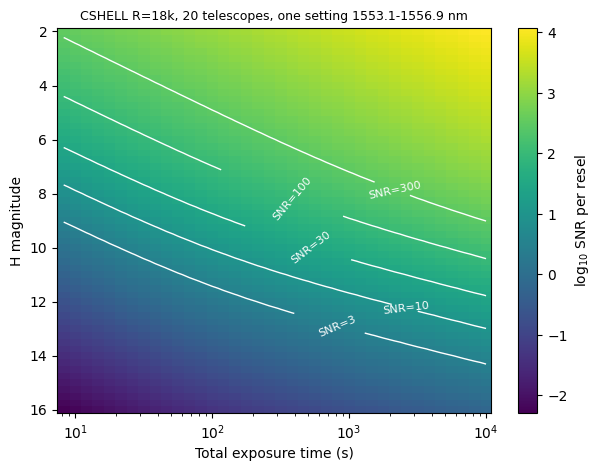

In [3]:
cs = Instrument.from_preset("cshell_r18000")
lo, hi = cs.setting_window(1555.0)               # one echelle setting (free spectral range ~2.5e-3 lambda)
cshell = LFASTETC(cs, n_telescopes=20, wavelength_min_nm=lo, wavelength_max_nm=hi)
kstar = Source.blackbody(4500, mag=0, band="H")
mags_h = np.linspace(2, 16, 57)
exps_h = exps[exps >= cshell.instrument.min_exptime]
snr_h = cshell.snr_grid(kstar, mags_h, exps_h, wavelength=(lo, hi))
plot_snr_map(mags_h, exps_h, snr_h, band="H", levels=(3, 10, 30, 100, 300),
             title=f"CSHELL R=18k, 20 telescopes, one setting {lo:.1f}-{hi:.1f} nm");

## Limiting magnitude versus wavelength

`plot_limiting_magnitude` solves for the magnitude that reaches the target SNR in each bin. For the
Bench the curve follows the throughput: deepest in the red, about a magnitude shallower at 420 nm.
The spikes are night-sky emission lines ([O I] 557.7 nm, Na D near 589 nm, [O I] 630.0/636.4 nm)
where the sky is locally much brighter.

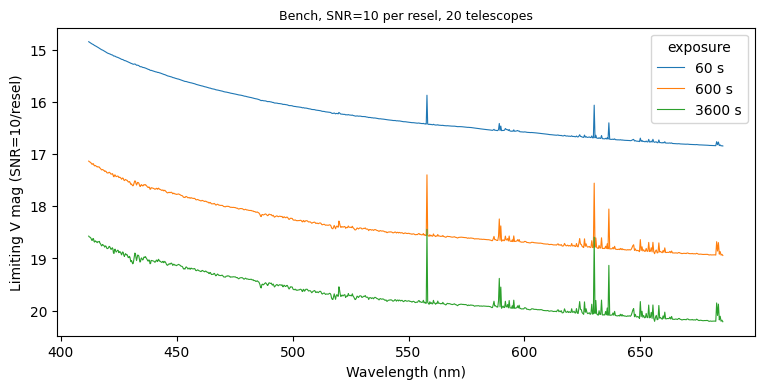

In [4]:
fig, ax = plt.subplots(figsize=(9, 4))
plot_limiting_magnitude(bench, gstar, exptimes=[60, 600, 3600], snr=10, ax=ax)
ax.set_title("Bench, SNR=10 per resel, 20 telescopes", fontsize=9);

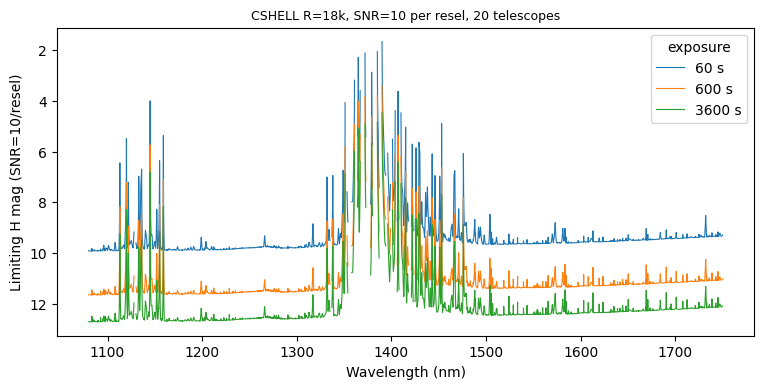

In [5]:
fig, ax = plt.subplots(figsize=(9, 4))
full = LFASTETC("cshell_r18000", n_telescopes=20)   # the whole CSHELL range, many echelle settings
plot_limiting_magnitude(full, kstar, exptimes=[60, 600, 3600], snr=10, ax=ax)
ax.set_title("CSHELL R=18k, SNR=10 per resel, 20 telescopes", fontsize=9);

Each wavelength in the CSHELL plot is what one echelle setting, about 2.5e-3 of the wavelength
wide, would give; the curve is not a single exposure. The gaps between 1.36 and 1.42 um are bins
where $K_{opt}$ is zero in the water band, and the ETC returns NaN there rather than a number.
The remaining structure is the throughput curve (tellurics and fiber coupling) on top of the sky.

## Scaling the number of telescopes

The 18 um fibers go through a 20-to-1 combiner. Within one array both $N_*$ and $N_{sky}$ grow
with $N$ while the detector terms do not, so the gain is better than $\sqrt{N}$ whenever read
noise or dark current matter. Beyond 20 telescopes the ETC assumes one combiner input per 20
telescopes, co-added incoherently (`telescopes_per_input=20`); the dotted curve is an idealised
single combiner for comparison. The 50 um fiber bypasses the combiner, so each telescope yields a
spectrum and the SNR grows as $\sqrt{N}$, but it couples about twice as much point-source light
and admits a 7.7 times larger patch of sky. The nominal 20-telescope prototype and the
100- and 200-telescope upgrade options are marked.

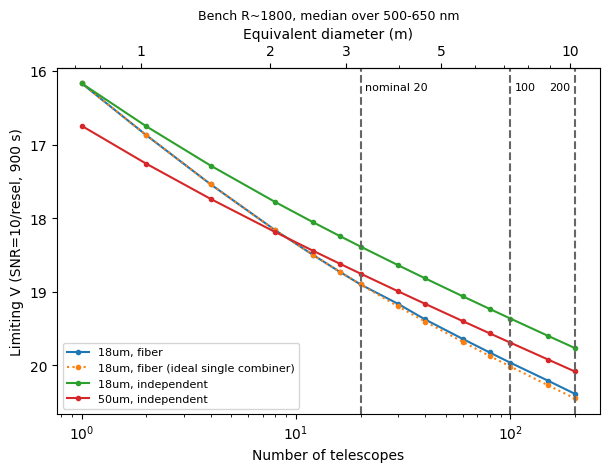

In [6]:
ns = np.array([1, 2, 4, 8, 12, 16, 20, 30, 40, 60, 80, 100, 150, 200])
configs = (("18um", "fiber", 20), ("18um", "fiber", None), ("18um", "independent", 20), ("50um", "independent", 20))
fig, ax = plt.subplots(figsize=(7, 4.5))
for fiber, combine, tpi in configs:
    lim = [LFASTETC("bench_r1800", telescope=Telescope(n_telescopes=int(n), fiber=fiber, combine=combine, telescopes_per_input=tpi))
           .limiting_magnitude(gstar, exptime=900, snr=10, wavelength=(500, 650)) for n in ns]
    ax.plot(ns, lim, marker='o', ms=3, ls=':' if tpi is None else '-',
            label=f"{fiber}, {combine}" + (" (ideal single combiner)" if tpi is None else ""))
ax.set_xscale('log'); ax.invert_yaxis()
ax.set_xlabel("Number of telescopes"); ax.set_ylabel("Limiting V (SNR=10/resel, 900 s)")
for n, txt, ha in ((20, "nominal 20", 'left'), (100, "100", 'left'), (200, "200", 'right')):
    ax.axvline(n, color='0.4', ls='--'); ax.text(n*1.05 if ha == 'left' else n/1.05, ax.get_ylim()[1]+0.3, txt, fontsize=8, ha=ha)
ax.legend(fontsize=8); ax.set_title("Bench R~1800, median over 500-650 nm", fontsize=9)
equivalent_diameter_axis(ax);

The top axis converts the number of telescopes into the diameter of a single telescope with the
same collecting area. The same comparison for CSHELL, where the 22 e$^-$ read noise and 5
e$^-$/s dark-plus-background current are large, shows the fiber combiner mattering more:

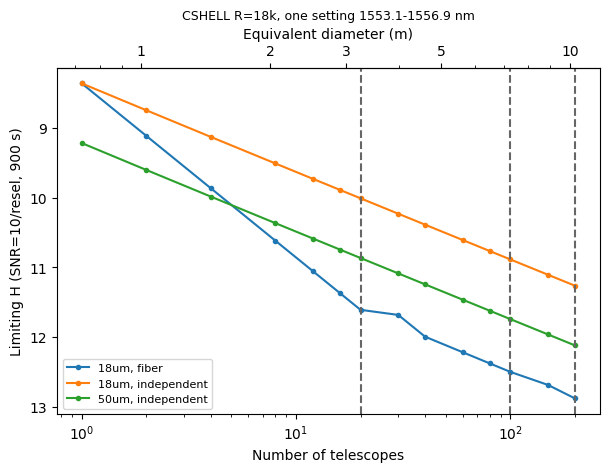

In [7]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for fiber, combine in (("18um", "fiber"), ("18um", "independent"), ("50um", "independent")):
    lim = [LFASTETC("cshell_r18000", telescope=Telescope(n_telescopes=int(n), fiber=fiber, combine=combine),
                    wavelength_min_nm=lo, wavelength_max_nm=hi).limiting_magnitude(kstar, 900, 10)
           for n in ns]
    ax.plot(ns, lim, marker='o', ms=3, label=f"{fiber}, {combine}")
ax.set_xscale('log'); ax.invert_yaxis()
ax.set_xlabel("Number of telescopes"); ax.set_ylabel("Limiting H (SNR=10/resel, 900 s)")
for n in (20, 100, 200):
    ax.axvline(n, color='0.4', ls='--')
ax.legend(fontsize=8); ax.set_title(f"CSHELL R=18k, one setting {lo:.1f}-{hi:.1f} nm", fontsize=9)
equivalent_diameter_axis(ax);

For the common case of one configuration and several exposure times there is a one-call helper,
`plot_vs_n_telescopes`. You pass a function that builds the ETC for a given $N$, so you decide
the fiber, the combiner and the bandpass.

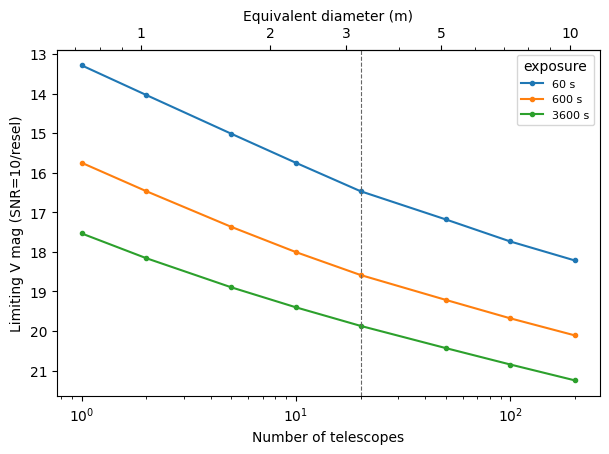

In [8]:
plot_vs_n_telescopes(lambda n: LFASTETC("bench_r1800", n_telescopes=n), gstar,
                     ns=[1, 2, 5, 10, 20, 50, 100, 200], exptimes=[60, 600, 3600], snr=10, wavelength=(500, 650));

## Dark time versus the bundled grey-time sky

The bundled SkyCalc table has the moon up (45 degrees away, 45 degrees altitude). Scattered
moonlight is about 57% of the 540 to 560 nm sky, giving V ~ 20.5 mag per square arcsecond, about
one magnitude brighter than dark Kitt Peak (V ~ 21.7 to 22.0 at zenith, Neugent & Massey 2010).
`Sky(scale=0.4)` is a crude dark-time estimate. It scales the airglow lines too, which is wrong
in detail; generate a proper SkyCalc table for real planning. In a 15-minute exposure the sky
matches a V ~ 19 star in 500-650 nm, so this matters for the faint end and not at all for bright stars.

In [9]:
for label, sky in (("grey (bundled)", Sky()), ("dark (x0.4)", Sky(scale=0.4))):
    e = LFASTETC("bench_r1800", n_telescopes=20, sky=sky)
    print(f"{label:15s}: V_lim(SNR=10, 900 s) = {e.limiting_magnitude(gstar, 900, 10, wavelength=(500, 650)):.2f}")

grey (bundled) : V_lim(SNR=10, 900 s) = 18.90
dark (x0.4)    : V_lim(SNR=10, 900 s) = 19.16


## Exposure time versus magnitude at fixed SNR

The most compact way to read off survey speed. The dashed line is one hour.

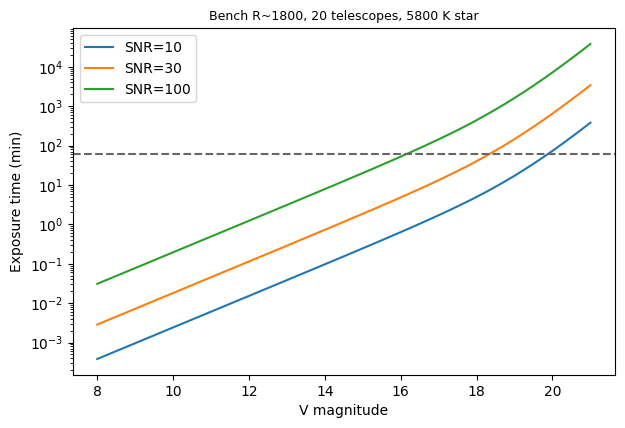

In [10]:
mags = np.linspace(8, 21, 53)
fig, ax = plt.subplots(figsize=(7, 4.5))
for snr_t in (10, 30, 100):
    t = bench.exptime_vs_mag(gstar, mags, snr=snr_t, wavelength=(500, 650))
    ax.plot(mags, t/60, label=f"SNR={snr_t}")
ax.set_yscale('log'); ax.set_xlabel("V magnitude"); ax.set_ylabel("Exposure time (min)")
ax.axhline(60, color='0.4', ls='--'); ax.legend(); ax.set_title("Bench R~1800, 20 telescopes, 5800 K star", fontsize=9);

## Things to try

* Redo the Bench sensitivity map for a 3500 K star normalised in I. Which contour moves most?
* Add `n_exp=10` to `snr_grid`. Where on the map does the extra read noise show?
* Change `telescopes_per_input` to 40 in the scaling plot. Why does the curve change only beyond
  N = 20?